In [29]:
from rdkit import Chem
from rdkit.Chem import rdChemReactions
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw

# 定义反应
reaction_smiles = 'ClCc1ccccc1.O=Cc1cc(F)c(O)c(F)c1>>O=Cc1cc(F)c(OCc2ccccc2)c(F)c1'

# 拆分反应物和产物
reactant_smiles = ['ClCc1ccccc1', 'O=Cc1cc(F)c(O)c(F)c1']
product_smiles = ['O=Cc1cc(F)c(OCc2ccccc2)c(F)c1']

reactants = [Chem.MolFromSmiles(smi) for smi in reactant_smiles]
products = [Chem.MolFromSmiles(smi) for smi in product_smiles]


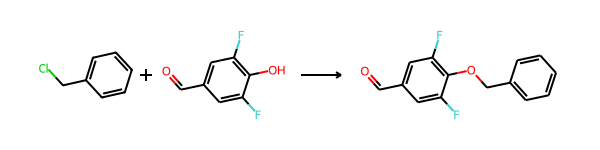

In [31]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdChemReactions

# 反应 SMARTS/SMILES
reaction_smiles = 'ClCc1ccccc1.O=Cc1cc(F)c(O)c(F)c1>>O=Cc1cc(F)c(OCc2ccccc2)c(F)c1'

# 创建反应对象
rxn = rdChemReactions.ReactionFromSmarts(reaction_smiles, useSmiles=True)

# 可视化反应（默认大小）
Draw.ReactionToImage(rxn, subImgSize=(150, 150))



Reactant Fragments:{'O=Cc1cc(F)c(O)c(F)c1', '[16*]c1ccccc1', '[8*]CCl'}
Product Fragments:{'[4*]C[8*]', '[3*]O[3*]', '[16*]c1ccccc1', '[16*]c1c(F)cc(C=O)cc1F'}


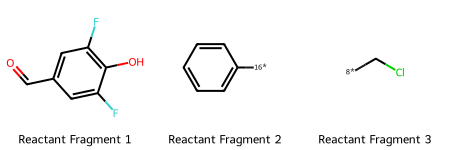

In [34]:
import os
from rdkit.Chem import RDConfig
from rdkit.Chem import BRICS
def brick_frags(mols):
    allfrags = set()
    for m in mols:
        pieces = BRICS.BRICSDecompose(m)
        allfrags.update(pieces)
    # print(len(allfrags))
    # print(allfrags)
    return allfrags
# print(sorted(allfrags)[:3])
react_frags = brick_frags(reactants)
print("Reactant Fragments:"+ str(react_frags))
prod_frags = brick_frags( products)
print("Product Fragments:" + str(prod_frags))

react_frag_mols = [Chem.MolFromSmiles(frag) for frag in react_frags]
prod_frag_mols = [Chem.MolFromSmiles(frag) for frag in prod_frags]

Draw.MolsToGridImage(react_frag_mols, molsPerRow=3, subImgSize=(150, 150), legends=[f"Reactant Fragment {i+1}" for i in range(len(react_frag_mols))])


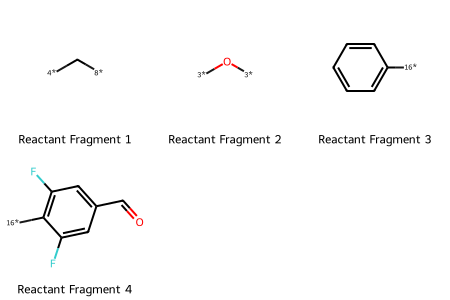

In [36]:
Draw.MolsToGridImage(prod_frag_mols, molsPerRow=3, subImgSize=(150, 150), legends=[f"Reactant Fragment {i+1}" for i in range(len(prod_frag_mols))])

共识别出 3 个 BRICS 片段
共识别出 4 个 BRICS 片段


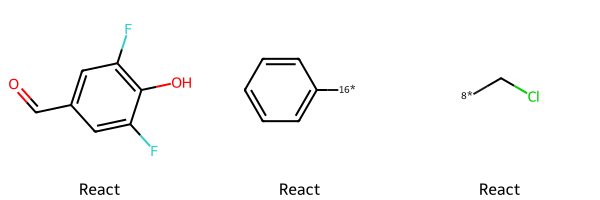

In [24]:
from rdkit import Chem
from rdkit.Chem import BRICS
from rdkit.Chem import Draw

def brick_frags(mols):
    allfrags = set()
    for m in mols:
        pieces = BRICS.BRICSDecompose(m)
        allfrags.update(pieces)
    print(f"共识别出 {len(allfrags)} 个 BRICS 片段")
    return allfrags

# 提取 BRICS 分段的 SMILES 字符串集合
react_frags = brick_frags(reactants)
prod_frags = brick_frags(products)

# 将 SMILES 转换为 Mol 对象
react_frag_mols = [Chem.MolFromSmiles(frag) for frag in react_frags]
prod_frag_mols = [Chem.MolFromSmiles(frag) for frag in prod_frags]

# 可视化
Draw.MolsToGridImage(react_frag_mols, molsPerRow=3, subImgSize=(200, 200), legends=["React"]*len(react_frag_mols))
# Draw.MolsToGridImage(prod_frag_mols, molsPerRow=3, subImgSize=(200, 200), legends=["Product"]*len(prod_frag_mols))


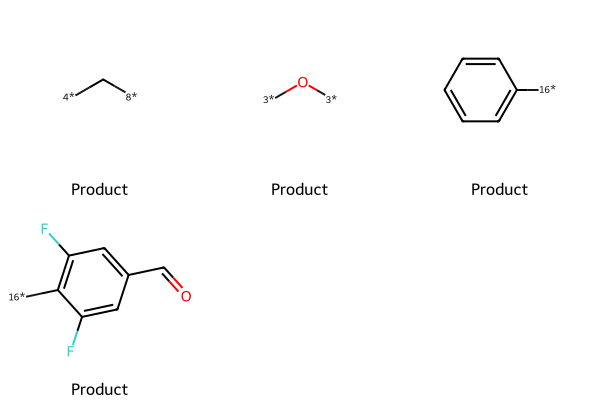

In [26]:
Draw.MolsToGridImage(prod_frag_mols, molsPerRow=3, subImgSize=(200, 200), legends=["Product"]*len(prod_frag_mols))